# EmoShield – Student Stress Prediction Model


In [1]:
import plotly
import ipywidgets

print("Plotly:", plotly.__version__)
print("ipywidgets:", ipywidgets.__version__)
print("Everything is ready!")

Plotly: 7.1.0
ipywidgets: 8.1.9
Everything is ready!


# Dashboard

✅ EmoShield dataset loaded successfully!
Dataset shape: (153, 17)

✅ Dashboard columns detected:
Stress       : How would you rate your current stress level?
Sleep        : How many hours do you sleep on average each night?
Screen Time  : On average, how many hours do you spend on your phone or other screens each day?
Study Hours  : On average, how many hours do you study each day?
Deadlines    : Do you currently have upcoming exams or assignment deadlines?
Overwhelmed  : How often do you feel overwhelmed?
Concentration: How often do you have difficulty concentrating because of stress?
Stress Source: What is the biggest source of your stress?


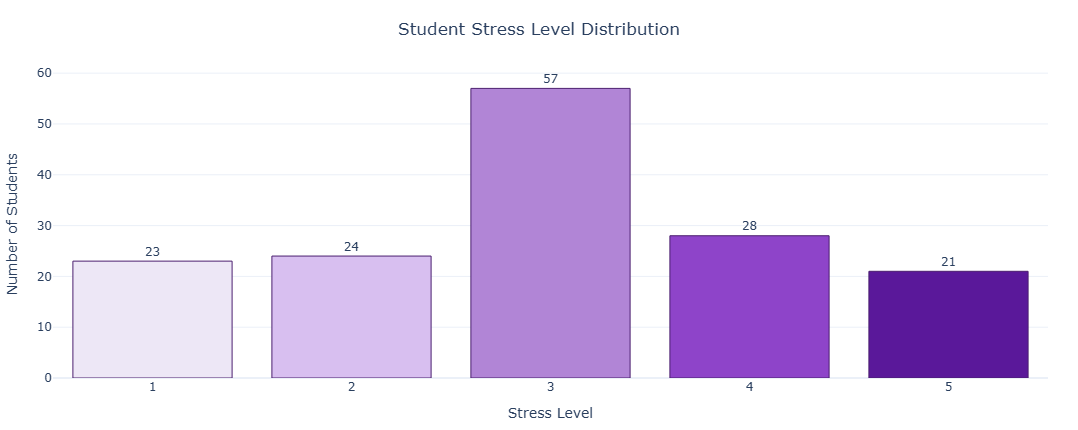

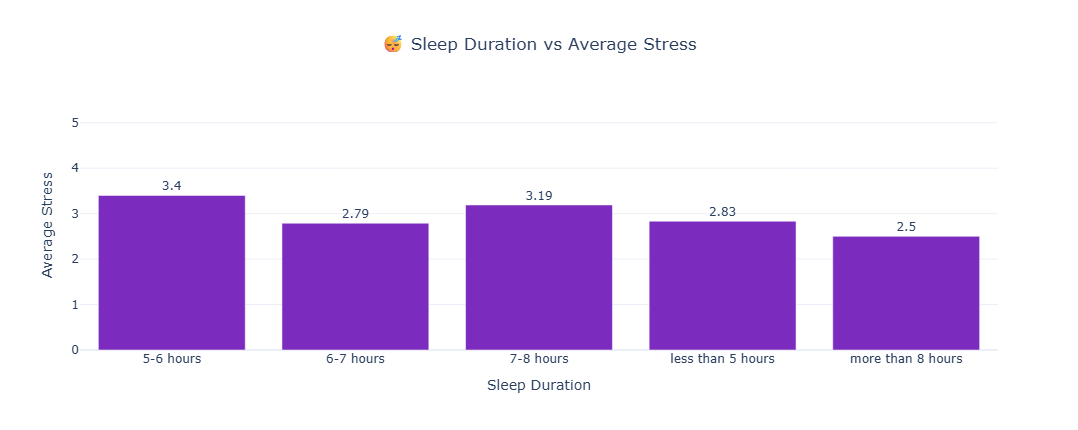

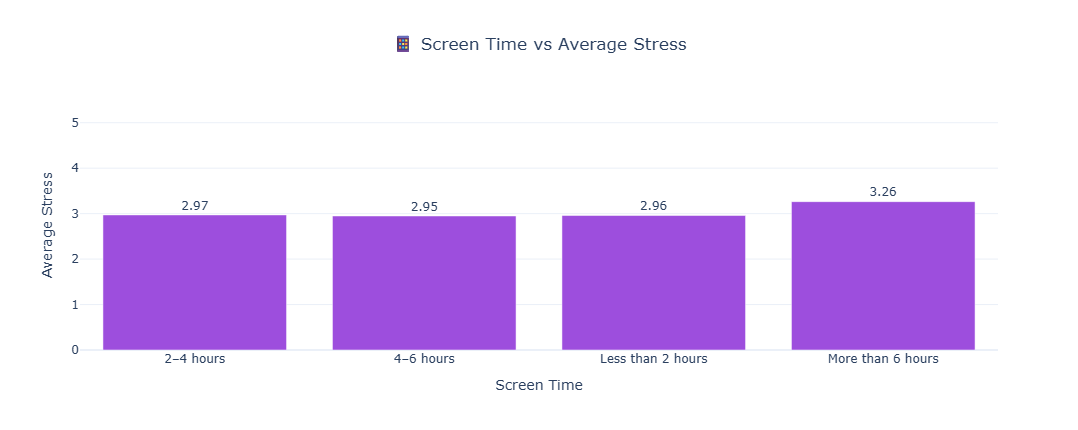

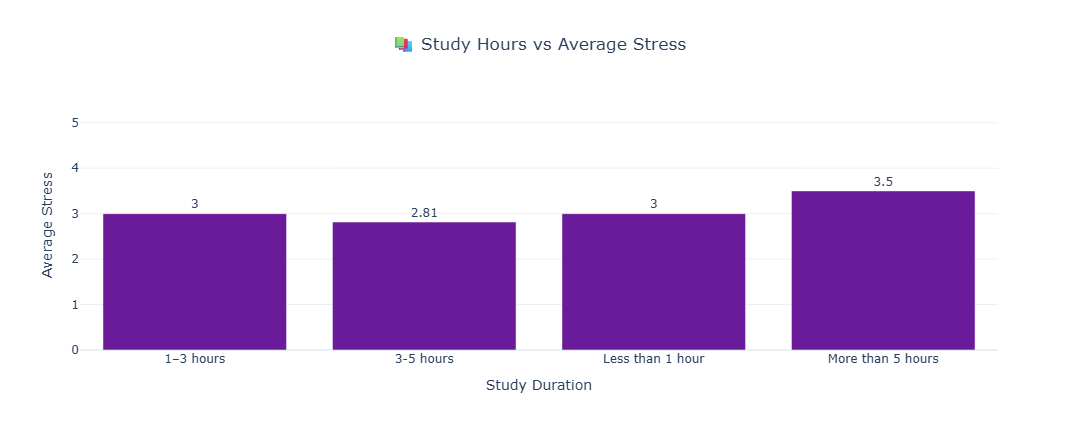

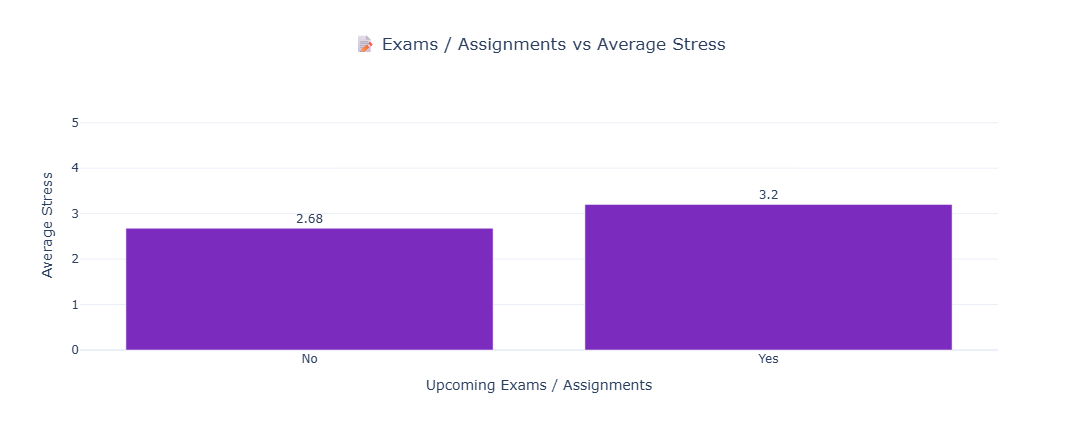

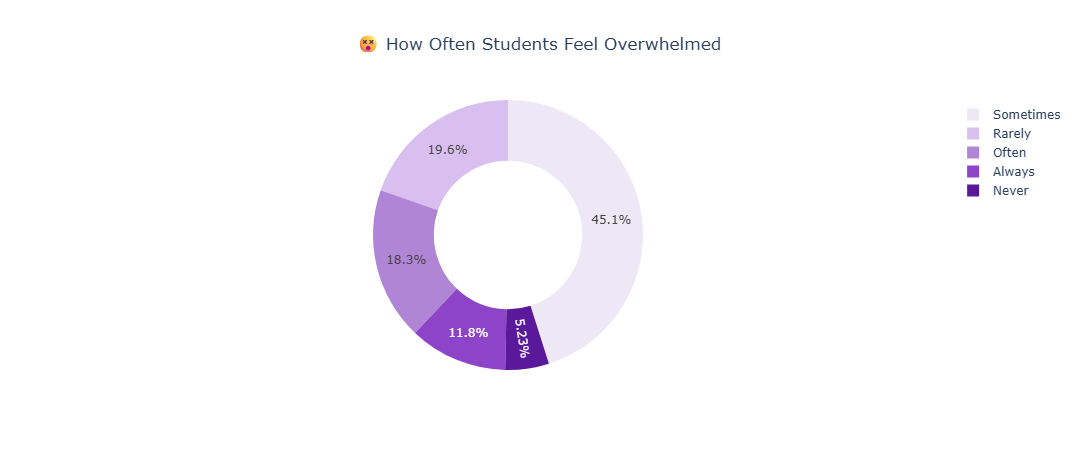

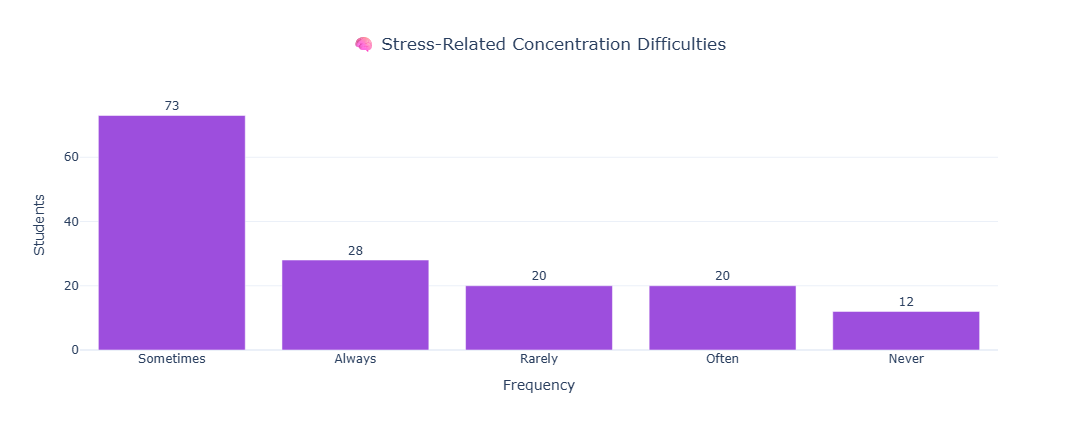

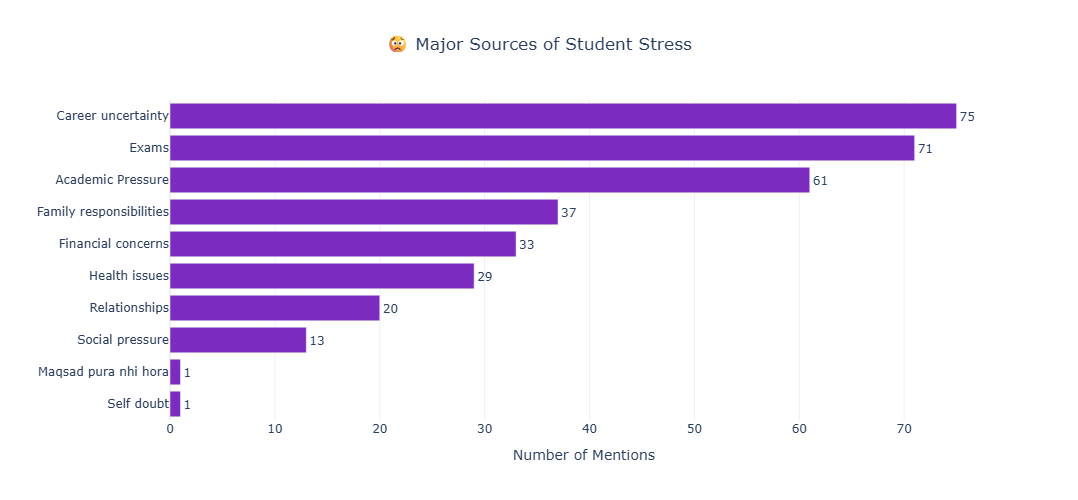

Dropdown(description='Select:', options=(('All Students', 'All'), ('Stress Level 1', 1), ('Stress Level 2', 2)…

Output()



💜 EMOSHIELD DASHBOARD READY!


In [15]:
# ============================================================
# 💜 EMOSHIELD - INTERACTIVE STUDENT WELLBEING DASHBOARD
# ============================================================

import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

from IPython.display import display, HTML, clear_output
import ipywidgets as widgets


# ============================================================
# 1. LOAD DATA
# ============================================================

FILE_NAME = "emo survey.csv"

df = pd.read_csv(r"C:\Users\Vaishnavi\Untitled Folder\emo survey.csv")

# Clean column names
df.columns = (
    df.columns
    .astype(str)
    .str.strip()
)

print("✅ EmoShield dataset loaded successfully!")
print("Dataset shape:", df.shape)


# ============================================================
# 2. AUTOMATIC COLUMN DETECTION
# ============================================================

def find_column(keywords, required=True):

    if isinstance(keywords, str):
        keywords = [keywords]

    # First try exact/contains matching
    for column in df.columns:

        column_lower = column.lower()

        if all(keyword.lower() in column_lower for keyword in keywords):
            return column

    if required:
        raise KeyError(
            f"Could not find column containing: {keywords}"
        )

    return None


# Automatically find the columns in your CSV

stress_col = find_column(
    ["current", "stress", "level"]
)

sleep_col = find_column(
    ["sleep"]
)

screen_col = find_column(
    ["phone", "screens"]
)

study_col = find_column(
    ["study", "each day"]
)

deadline_col = find_column(
    ["upcoming", "exams"]
)

overwhelmed_col = find_column(
    ["overwhelmed"]
)

concentration_col = find_column(
    ["concentrating"]
)

source_col = find_column(
    ["biggest", "source", "stress"],
    required=False
)


print("\n✅ Dashboard columns detected:")
print("Stress       :", stress_col)
print("Sleep        :", sleep_col)
print("Screen Time  :", screen_col)
print("Study Hours  :", study_col)
print("Deadlines    :", deadline_col)
print("Overwhelmed  :", overwhelmed_col)
print("Concentration:", concentration_col)
print("Stress Source:", source_col)


# ============================================================
# 3. PREPARE DATA
# ============================================================

dashboard_df = df.copy()

dashboard_df[stress_col] = pd.to_numeric(
    dashboard_df[stress_col],
    errors="coerce"
)

dashboard_df = dashboard_df.dropna(
    subset=[stress_col]
)

dashboard_df[stress_col] = (
    dashboard_df[stress_col]
    .astype(int)
)


# ============================================================
# 4. PURPLE EMOSHIELD DESIGN
# ============================================================

display(HTML("""

<style>

.emo-wrapper {
    font-family: Arial, sans-serif;
}

.emo-hero {
    background: linear-gradient(
        135deg,
        #24103F,
        #4B1F6F,
        #7B2CBF,
        #9D4EDD
    );

    padding: 35px;
    border-radius: 25px;

    color: white;

    margin-bottom: 25px;

    box-shadow:
        0 12px 35px
        rgba(75, 31, 111, 0.25);
}

.emo-hero h1 {
    font-size: 44px;
    margin: 0;
}

.emo-hero p {
    margin: 8px 0;
}

.emo-subtitle {
    font-size: 20px;
}

.emo-tagline {
    font-size: 14px;
    opacity: 0.85;
}

.kpi-row {
    display: flex;
    gap: 15px;
    flex-wrap: wrap;
    margin-bottom: 25px;
}

.kpi-card {
    flex: 1;
    min-width: 180px;

    background: white;

    border-radius: 18px;

    padding: 22px;

    border: 1px solid #eadcf5;

    box-shadow:
        0 8px 25px
        rgba(70, 30, 100, 0.08);
}

.kpi-icon {
    font-size: 27px;
}

.kpi-value {
    color: #5A189A;
    font-size: 30px;
    font-weight: bold;
    margin-top: 5px;
}

.kpi-label {
    color: #777;
    font-size: 13px;
}

.section-title {
    background: linear-gradient(
        90deg,
        #F3E8FF,
        #FAF7FD
    );

    border-left: 6px solid #7B2CBF;

    padding: 14px 20px;

    border-radius: 12px;

    margin: 25px 0 15px 0;

    color: #4B1F6F;
}

.footer {
    background: #24103F;

    color: white;

    padding: 25px;

    border-radius: 20px;

    text-align: center;

    margin-top: 30px;
}

</style>

<div class="emo-wrapper">

<div class="emo-hero">

<h1>💜 EmoShield</h1>

<p class="emo-subtitle">
Student Wellbeing Intelligence Dashboard
</p>

<p class="emo-tagline">
Understand • Analyze • Predict • Support
</p>

</div>

</div>

"""))


# ============================================================
# 5. KPI CALCULATIONS
# ============================================================

total_students = len(dashboard_df)

average_stress = round(
    dashboard_df[stress_col].mean(),
    2
)

highest_stress = int(
    dashboard_df[stress_col].max()
)

high_stress_students = (
    dashboard_df[stress_col] >= 4
).sum()


# Students with upcoming deadlines
deadline_series = (
    dashboard_df[deadline_col]
    .astype(str)
    .str.strip()
    .str.lower()
)

deadline_yes = deadline_series.isin(
    ["yes", "yes, currently", "true"]
).sum()


# ============================================================
# 6. KPI CARDS
# ============================================================

display(HTML(f"""

<div class="kpi-row">

<div class="kpi-card">
    <div class="kpi-icon">👥</div>
    <div class="kpi-value">{total_students}</div>
    <div class="kpi-label">Students Surveyed</div>
</div>

<div class="kpi-card">
    <div class="kpi-icon">📊</div>
    <div class="kpi-value">{average_stress}/5</div>
    <div class="kpi-label">Average Reported Stress</div>
</div>

<div class="kpi-card">
    <div class="kpi-icon">⚠️</div>
    <div class="kpi-value">{high_stress_students}</div>
    <div class="kpi-label">High Stress Responses</div>
</div>

<div class="kpi-card">
    <div class="kpi-icon">📚</div>
    <div class="kpi-value">{deadline_yes}</div>
    <div class="kpi-label">Students With Deadlines</div>
</div>

</div>

"""))


# ============================================================
# 7. STRESS DISTRIBUTION
# ============================================================

display(HTML("""
<div class="section-title">
<h3>📊 Stress Overview</h3>
</div>
"""))


stress_counts = (
    dashboard_df[stress_col]
    .value_counts()
    .sort_index()
)

stress_colors = [
    "#EDE7F6",
    "#D8BFF0",
    "#B185D6",
    "#8E44C9",
    "#5A189A"
]

fig = go.Figure()

fig.add_trace(
    go.Bar(
        x=stress_counts.index,
        y=stress_counts.values,

        text=stress_counts.values,

        textposition="outside",

        marker=dict(
            color=[
                stress_colors[
                    min(int(level)-1, 4)
                ]
                for level in stress_counts.index
            ],

            line=dict(
                color="#4B1F6F",
                width=1
            )
        ),

        hovertemplate=
        "<b>Stress Level %{x}</b><br>" +
        "Students: %{y}<extra></extra>"
    )
)

fig.update_layout(

    title="Student Stress Level Distribution",

    template="plotly_white",

    title_x=0.5,

    height=430,

    xaxis=dict(
        title="Stress Level",
        dtick=1
    ),

    yaxis=dict(
        title="Number of Students"
    ),

    margin=dict(
        l=50,
        r=30,
        t=70,
        b=50
    )
)

fig.show()


# ============================================================
# 8. WELLBEING PATTERNS
# ============================================================

display(HTML("""
<div class="section-title">
<h3>🧠 Lifestyle & Wellbeing Patterns</h3>
</div>
"""))


# ============================================================
# 9. SLEEP VS STRESS
# ============================================================

sleep_data = (
    dashboard_df
    .groupby(sleep_col)[stress_col]
    .mean()
    .reset_index()
)

sleep_data.columns = [
    "Sleep",
    "Average Stress"
]

fig = px.bar(
    sleep_data,

    x="Sleep",

    y="Average Stress",

    text=sleep_data["Average Stress"].round(2),

    title="😴 Sleep Duration vs Average Stress"
)

fig.update_traces(
    marker_color="#7B2CBF",

    textposition="outside",

    hovertemplate=
    "<b>%{x}</b><br>" +
    "Average Stress: %{y:.2f}<extra></extra>"
)

fig.update_layout(
    template="plotly_white",

    title_x=0.5,

    height=430,

    yaxis=dict(
        range=[0, 5.5],
        title="Average Stress"
    ),

    xaxis_title="Sleep Duration"
)

fig.show()


# ============================================================
# 10. SCREEN TIME VS STRESS
# ============================================================

screen_data = (
    dashboard_df
    .groupby(screen_col)[stress_col]
    .mean()
    .reset_index()
)

screen_data.columns = [
    "Screen Time",
    "Average Stress"
]

fig = px.bar(
    screen_data,

    x="Screen Time",

    y="Average Stress",

    text=screen_data["Average Stress"].round(2),

    title="📱 Screen Time vs Average Stress"
)

fig.update_traces(
    marker_color="#9D4EDD",

    textposition="outside"
)

fig.update_layout(
    template="plotly_white",

    title_x=0.5,

    height=430,

    yaxis=dict(
        range=[0, 5.5],
        title="Average Stress"
    ),

    xaxis_title="Screen Time"
)

fig.show()


# ============================================================
# 11. STUDY HOURS VS STRESS
# ============================================================

study_data = (
    dashboard_df
    .groupby(study_col)[stress_col]
    .mean()
    .reset_index()
)

study_data.columns = [
    "Study Hours",
    "Average Stress"
]

fig = px.bar(
    study_data,

    x="Study Hours",

    y="Average Stress",

    text=study_data["Average Stress"].round(2),

    title="📚 Study Hours vs Average Stress"
)

fig.update_traces(
    marker_color="#6A1B9A",

    textposition="outside"
)

fig.update_layout(
    template="plotly_white",

    title_x=0.5,

    height=430,

    yaxis=dict(
        range=[0, 5.5],
        title="Average Stress"
    ),

    xaxis_title="Study Duration"
)

fig.show()


# ============================================================
# 12. ACADEMIC DEADLINES VS STRESS
# ============================================================

display(HTML("""
<div class="section-title">
<h3>📚 Academic Pressure</h3>
</div>
"""))


deadline_data = (
    dashboard_df
    .groupby(deadline_col)[stress_col]
    .mean()
    .reset_index()
)

deadline_data.columns = [
    "Deadline Status",
    "Average Stress"
]

fig = px.bar(
    deadline_data,

    x="Deadline Status",

    y="Average Stress",

    text=deadline_data["Average Stress"].round(2),

    title="📝 Exams / Assignments vs Average Stress"
)

fig.update_traces(
    marker_color="#7B2CBF",

    textposition="outside"
)

fig.update_layout(
    template="plotly_white",

    title_x=0.5,

    height=430,

    yaxis=dict(
        range=[0, 5.5],
        title="Average Stress"
    ),

    xaxis_title="Upcoming Exams / Assignments"
)

fig.show()


# ============================================================
# 13. FEELING OVERWHELMED
# ============================================================

display(HTML("""
<div class="section-title">
<h3>💭 Emotional Wellbeing</h3>
</div>
"""))


overwhelmed_data = (
    dashboard_df[overwhelmed_col]
    .value_counts()
    .reset_index()
)

overwhelmed_data.columns = [
    "Frequency",
    "Students"
]

fig = px.pie(

    overwhelmed_data,

    names="Frequency",

    values="Students",

    hole=0.55,

    title="😵 How Often Students Feel Overwhelmed"
)

fig.update_traces(
    marker=dict(
        colors=[
            "#EDE7F6",
            "#D8BFF0",
            "#B185D6",
            "#8E44C9",
            "#5A189A"
        ]
    ),

    hovertemplate=
    "<b>%{label}</b><br>" +
    "Students: %{value}<br>" +
    "Percentage: %{percent}<extra></extra>"
)

fig.update_layout(
    template="plotly_white",

    title_x=0.5,

    height=450
)

fig.show()


# ============================================================
# 14. CONCENTRATION DIFFICULTY
# ============================================================

concentration_data = (
    dashboard_df[concentration_col]
    .value_counts()
    .reset_index()
)

concentration_data.columns = [
    "Frequency",
    "Students"
]

fig = px.bar(

    concentration_data,

    x="Frequency",

    y="Students",

    text="Students",

    title="🧠 Stress-Related Concentration Difficulties"
)

fig.update_traces(
    marker_color="#9D4EDD",

    textposition="outside"
)

fig.update_layout(
    template="plotly_white",

    title_x=0.5,

    height=430
)

fig.show()


# ============================================================
# 15. MAJOR STRESS SOURCES
# ============================================================

if source_col is not None:

    source_data = (
        dashboard_df[source_col]
        .dropna()
        .astype(str)
        .str.split(",")
        .explode()
        .str.strip()
    )

    source_data = source_data[
        source_data != ""
    ]

    source_counts = (
        source_data
        .value_counts()
        .head(10)
        .sort_values()
    )

    fig = go.Figure()

    fig.add_trace(
        go.Bar(

            x=source_counts.values,

            y=source_counts.index,

            orientation="h",

            text=source_counts.values,

            textposition="outside",

            marker=dict(
                color="#7B2CBF"
            ),

            hovertemplate=
            "<b>%{y}</b><br>" +
            "Mentions: %{x}<extra></extra>"
        )
    )

    fig.update_layout(

        title="😟 Major Sources of Student Stress",

        template="plotly_white",

        title_x=0.5,

        height=500,

        xaxis_title="Number of Mentions",

        yaxis_title=""
    )

    fig.show()


# ============================================================
# 16. INTERACTIVE STRESS FILTER
# ============================================================

display(HTML("""
<div class="section-title">
<h3>🎛️ Interactive Stress Explorer</h3>
</div>

<p style="
    color:#666;
    font-size:14px;
">
Select a stress level to explore the corresponding student responses.
</p>
"""))


stress_dropdown = widgets.Dropdown(

    options=[
        ("All Students", "All"),
        ("Stress Level 1", 1),
        ("Stress Level 2", 2),
        ("Stress Level 3", 3),
        ("Stress Level 4", 4),
        ("Stress Level 5", 5)
    ],

    value="All",

    description="Select:",

    style={
        "description_width": "initial"
    }
)


output = widgets.Output()


def update_stress_chart(change):

    if change["name"] != "value":
        return

    with output:

        clear_output(wait=True)

        selected = change["new"]

        if selected == "All":

            filtered = dashboard_df.copy()

            title = "All Students"

        else:

            filtered = dashboard_df[
                dashboard_df[stress_col] == selected
            ].copy()

            title = f"Stress Level {selected}"


        # Summary
        count = len(filtered)

        if count > 0:

            avg = round(
                filtered[stress_col].mean(),
                2
            )

        else:

            avg = 0


        display(HTML(f"""

        <div style="
            background:#F3E8FF;
            border-left:6px solid #7B2CBF;
            padding:15px;
            border-radius:12px;
            margin:15px 0;
        ">

        <b style="color:#5A189A;">
        {title}
        </b>

        &nbsp;&nbsp; | &nbsp;&nbsp;

        Students: <b>{count}</b>

        &nbsp;&nbsp; | &nbsp;&nbsp;

        Average Stress:
        <b>{avg}/5</b>

        </div>

        """))


        if count == 0:

            print("No students found.")

            return


        # Distribution
        counts = (
            filtered[stress_col]
            .value_counts()
            .sort_index()
        )


        fig = go.Figure(

            go.Bar(

                x=counts.index,

                y=counts.values,

                text=counts.values,

                textposition="outside",

                marker_color="#7B2CBF",

                hovertemplate=
                "<b>Stress Level %{x}</b><br>" +
                "Students: %{y}<extra></extra>"
            )
        )


        fig.update_layout(

            title=f"Stress Distribution — {title}",

            template="plotly_white",

            title_x=0.5,

            height=400,

            xaxis=dict(
                dtick=1,
                title="Stress Level"
            ),

            yaxis_title="Students"
        )


        fig.show()


stress_dropdown.observe(
    update_stress_chart,
    names="value"
)


display(stress_dropdown)

display(output)


# Display initial result
update_stress_chart({
    "name": "value",
    "new": "All"
})


# ============================================================
# 17. FOOTER
# ============================================================

display(HTML("""

<div class="footer">

<h2 style="margin:0;">
💜 EmoShield
</h2>

<p>
Student Wellbeing • Data Analytics • Machine Learning
</p>

<p style="
    font-size:12px;
    opacity:0.75;
">
An academic prototype for student wellbeing awareness.
The survey-based stress estimate is not a medical diagnosis.
</p>

</div>

"""))

print("\n")
print("💜 EMOSHIELD DASHBOARD READY!")

# Importing Required Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

##  Loading the Google Form Dataset

In [6]:
df = pd.read_csv(
    r"C:\Users\Vaishnavi\Downloads\EMOSHEILD SURVEY - Form Responses 1 (1).csv"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (153, 17)


##  Exploring the Dataset

In [3]:
df.head(5)

,Timestamp,Name,Age,Course,Year Of Study,"On average, how many hours do you study each day?","On average, how many hours do you spend on your phone or other screens each day?",How many hours do you sleep on average each night?,How often do you exercise or engage in physical activity?,Do you currently have upcoming exams or assignment deadlines?,What is the biggest source of your stress?,How often do you feel overwhelmed?,How often do you have difficulty concentrating because of stress?,"When you feel stressed, what symptoms do you usually experience?",Do you feel you have someone you can reach out to when you're emotionally struggling?,How would you rate your current stress level?,Email ID
0,8/5/2026 22:14:42,Vaishnavi Kuchekar,19,BCA,Third,1–3 hours,4–6 hours,6-7 hours,3-5 times a week,Yes,Academic Pressure,Sometimes,Rarely,Headache,Yes,1,NaN
1,8/5/2026 22:20:48,Sakshi patil,23,BCA,Final,1–3 hours,4–6 hours,6-7 hours,Rarely,Yes,Health issues,Often,Often,"Headache, Anxiety, Difficulty sleeping, Rapid ...",Sometimes,5,NaN
2,8/5/2026 22:24:46,Neelima Indurkar,27,M.Sc.,Final,Less than 1 hour,More than 6 hours,7-8 hours,Never,No,"Career uncertainty, Financial concerns",Sometimes,Sometimes,Irritability,Sometimes,4,NaN
3,8/5/2026 22:25:29,Prachi Pawar,23,BBA,Final,1–3 hours,2–4 hours,7-8 hours,Rarely,No,"Career uncertainty, Financial concerns, Family...",Often,Always,"fatigue, Anxiety, Irritability, Loss of focus",Sometimes,3,NaN
4,8/5/2026 22:25:55,Ram,23,B pharm,Final,1–3 hours,Less than 2 hours,7-8 hours,Rarely,No,"Academic Pressure, Exams, Career uncertainty",Rarely,Always,"Headache, Loss of focus",Yes,1,NaN


##  Cleaning Column Names

Extra spaces in the column names are removed to make the dataset easier to work with.

In [4]:
df.columns = df.columns.str.strip()

print("Column names cleaned successfully!")
print(df.columns.tolist())

Column names cleaned successfully!
['Timestamp', 'Name', 'Age', 'Course', 'Year Of Study', 'On average, how many hours do you study each day?', 'On average, how many hours do you spend on your phone or other screens each day?', 'How many hours do you sleep on average each night?', 'How often do you exercise or engage in physical activity?', 'Do you currently have upcoming exams or assignment deadlines?', 'What is the biggest source of your stress?', 'How often do you feel overwhelmed?', 'How often do you have difficulty concentrating because of stress?', 'When you feel stressed, what symptoms do you usually experience?', "Do you feel you have someone you can reach out to when you're emotionally struggling?", 'How would you rate your current stress level?', 'Email ID']


##  Dataset Information

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 153 entries, 0 to 152
Data columns (total 17 columns):
 #   Column                                                                                 Non-Null Count  Dtype
---  ------                                                                                 --------------  -----
 0   Timestamp                                                                              153 non-null    str  
 1   Name                                                                                   153 non-null    str  
 2   Age                                                                                    153 non-null    str  
 3   Course                                                                                 153 non-null    str  
 4   Year Of Study                                                                          153 non-null    str  
 5   On average, how many hours do you study each day?                                      153 non-null    

##  Defining the Target Variable

The target variable is the student's current stress level, measured
on a scale from 1 to 5.

In [6]:
target = "How would you rate your current stress level?"

# Convert stress level to numeric
df[target] = pd.to_numeric(
    df[target],
    errors="coerce"
)

# Remove rows where the target is missing
df = df.dropna(subset=[target])

print("Target variable:", target)
print("Number of responses:", len(df))

Target variable: How would you rate your current stress level?
Number of responses: 153


##  Stress Level Distribution

The distribution of students across the different stress-level categories is examined and visualized.

In [7]:
print("Stress Level Distribution:")
print(df[target].value_counts().sort_index())

Stress Level Distribution:
How would you rate your current stress level?
1    23
2    24
3    57
4    28
5    21
Name: count, dtype: int64


##  Feature Selection

Academic, lifestyle, and wellbeing-related factors are selected as input features for predicting the student's stress level.

In [8]:
features = [
    "Age",
    "On average, how many hours do you study each day?",
    "On average, how many hours do you spend on your phone or other screens each day?",
    "How many hours do you sleep on average each night?",
    "How often do you exercise or engage in physical activity?",
    "Do you currently have upcoming exams or assignment deadlines?",
    "How often do you feel overwhelmed?",
    "How often do you have difficulty concentrating because of stress?",
    "Do you feel you have someone you can reach out to when you're emotionally struggling?"
]

X = df[features].copy()
y = df[target].copy()

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Input features shape: (153, 9)
Target shape: (153,)


##  Cleaning the Age Column

The Age column is converted into numerical values so that it can be used by the machine learning model.

In [9]:
X["Age"] = (
    X["Age"]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
)

X["Age"] = pd.to_numeric(
    X["Age"],
    errors="coerce"
)

# Fill missing ages with the median
X["Age"] = X["Age"].fillna(
    X["Age"].median()
)

print("Age cleaned successfully!")
print(X["Age"].unique())

Age cleaned successfully!
[19. 23. 27. 21. 20. 17. 18. 22. 24. 16. 30. 25. 36. 28. 14. 34.]


##  Handling Missing Values

Missing values in the input features are handled to prepare the dataset for machine learning.

In [11]:
print(X.isnull().sum())

Age                                                                                      0
On average, how many hours do you study each day?                                        0
On average, how many hours do you spend on your phone or other screens each day?         0
How many hours do you sleep on average each night?                                       0
How often do you exercise or engage in physical activity?                                0
Do you currently have upcoming exams or assignment deadlines?                            0
How often do you feel overwhelmed?                                                       0
How often do you have difficulty concentrating because of stress?                        0
Do you feel you have someone you can reach out to when you're emotionally struggling?    0
dtype: int64


##  Splitting the Dataset

The dataset is divided into training and testing sets. 80% of the data is used for training and 20% is used for testing.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 122
Testing samples: 31


##  Identifying Feature Types

The input variables are separated into numerical and categorical features for appropriate preprocessing.

In [13]:
categorical_features = X.select_dtypes(
    include=["object"]
).columns

numeric_features = X.select_dtypes(
    exclude=["object"]
).columns

print("Categorical features:")
print(list(categorical_features))

print("\nNumerical features:")
print(list(numeric_features))

Categorical features:
['On average, how many hours do you study each day?', 'On average, how many hours do you spend on your phone or other screens each day?', 'How many hours do you sleep on average each night?', 'How often do you exercise or engage in physical activity?', 'Do you currently have upcoming exams or assignment deadlines?', 'How often do you feel overwhelmed?', 'How often do you have difficulty concentrating because of stress?', "Do you feel you have someone you can reach out to when you're emotionally struggling?"]

Numerical features:
['Age']


C:\Users\Vaishnavi\AppData\Local\Temp\ipykernel_15404\2908071426.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


##  Encoding Categorical Features

Categorical responses are converted into numerical representations using One-Hot Encoding.

In [14]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            "passthrough",
            numeric_features
        )
    ]
)

print("Preprocessing setup completed!")

Preprocessing setup completed!


##  Creating the Random Forest Model

A Random Forest Classifier is created to predict the student's stress level based on the selected features.

In [15]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42,
                class_weight="balanced"
            )
        )
    ]
)

print("Random Forest model created!")

Random Forest model created!


##  Training the Model

The Random Forest model is trained using the training dataset.

In [16]:
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


##  Making Stress Level Predictions

The trained model is used to predict stress levels for the unseen testing dataset.

In [17]:
y_pred = model.predict(X_test)

print("Predicted Stress Levels:")
print(y_pred)

Predicted Stress Levels:
[4 2 1 3 2 5 5 3 5 1 3 3 5 4 3 4 4 1 2 3 3 3 1 3 5 3 2 3 3 2 3]


##  Comparing Actual and Predicted Values

The actual stress levels are compared with the stress levels predicted by the model.

In [18]:
comparison = pd.DataFrame({
    "Actual Stress Level": y_test.values,
    "Predicted Stress Level": y_pred
})

comparison.head(10)

,Actual Stress Level,Predicted Stress Level
0,2,4
1,3,2
2,5,1
3,4,3
4,1,2
5,3,5
6,3,5
7,4,3
8,2,5
9,1,1


##  Evaluating Model Accuracy

The accuracy of the Random Forest model is calculated to measure its classification performance.

In [19]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

print(
    "Model Accuracy:",
    round(accuracy * 100, 2),
    "%"
)

Model Accuracy: 29.03 %


##  Classification Report

Precision, recall, F1-score, and support are calculated to provide a detailed evaluation of the model.

In [20]:
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           1       0.25      0.20      0.22         5
           2       0.00      0.00      0.00         5
           3       0.54      0.64      0.58        11
           4       0.25      0.17      0.20         6
           5       0.00      0.00      0.00         4

    accuracy                           0.29        31
   macro avg       0.21      0.20      0.20        31
weighted avg       0.28      0.29      0.28        31



##  Confusion Matrix

A confusion matrix is used to visualize the correct and incorrect stress-level predictions made by the model.

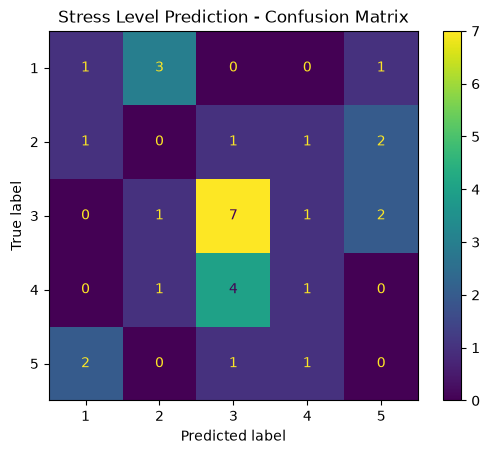

In [21]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

plt.title("Stress Level Prediction - Confusion Matrix")
plt.show()

##  Predicting Stress for a New Student

The trained model is used to demonstrate how the stress level of a new student can be predicted from their survey responses.

In [22]:
new_student = pd.DataFrame({
    "Age": [20],

    "On average, how many hours do you study each day?": [
        "3-5 hours"
    ],

    "On average, how many hours do you spend on your phone or other screens each day?": [
        "4–6 hours"
    ],

    "How many hours do you sleep on average each night?": [
        "5-6 hours"
    ],

    "How often do you exercise or engage in physical activity?": [
        "Rarely"
    ],

    "Do you currently have upcoming exams or assignment deadlines?": [
        "Yes"
    ],

    "How often do you feel overwhelmed?": [
        "Often"
    ],

    "How often do you have difficulty concentrating because of stress?": [
        "Often"
    ],

    "Do you feel you have someone you can reach out to when you're emotionally struggling?": [
        "Sometimes"
    ]
})

prediction = model.predict(new_student)

print("Predicted Stress Level:", prediction[0], "out of 5")

Predicted Stress Level: 5 out of 5


##  Prediction Probabilities

The model's predicted probabilities for each stress-level category are displayed.

In [23]:
probabilities = model.predict_proba(new_student)

probability_table = pd.DataFrame(
    probabilities * 100,
    columns=[
        f"Stress Level {int(c)}"
        for c in model.classes_
    ]
)

probability_table

,Stress Level 1,Stress Level 2,Stress Level 3,Stress Level 4,Stress Level 5
0,6.5,19.0,13.5,26.5,34.5


##  Final Stress Prediction

The predicted stress level for the new student is displayed clearly.

In [24]:
predicted_level = int(prediction[0])

print("=" * 45)
print("       EMOSHIELD STRESS PREDICTION")
print("=" * 45)
print(f"Predicted Stress Level: {predicted_level}/5")
print("=" * 45)

       EMOSHIELD STRESS PREDICTION
Predicted Stress Level: 5/5


# Conclusion

A Random Forest classification model was developed using data collected through the EmoShield Google Form to predict student stress levels from 1 to 5. 
The model was evaluated using accuracy, classification metrics, and a confusion matrix.

The results demonstrate how survey data can be used to develop a student stress prediction prototype.
    However, a larger dataset would be required for more reliable real-world predictions.